# 17 — The Output Contract: Calibrating What the System Is Allowed to Say

Sixteen notebooks have produced a set of measurements. None of them is yet a
**statement a system could make to an engineer**, because three of them are
uncalibrated:

- Notebook 15 left a **may-be-wrong flag** at **0.752** AUROC — explicitly "a
  measurement, not an operating point", with no threshold and no stated cost.
- Notebook 16 left a **RUL floor** with a safety–cost curve and declined to pick
  a quantile, saying the curve "is the thing a deployment picks a point on, not
  a number this notebook should pick for it".
- Notebook 14 left stage 2's scope condition — *outer race or inner race,
  conditional on it being one of the two* — as prose rather than as a rate.

Notebook 16's next-steps tied the first two together with a specific conjecture:

> *the two should be calibrated together, since a **low-confidence race call
> should widen the RUL band***.

That conjecture is the reason this is one notebook rather than two, and it is
among the first things tested here. It does not survive.

Nothing new is computed from raw data. The stage-1 alarm, the stage-2 race model
and the RUL forest are rebuilt exactly as notebooks 14, 15 and 16 built them,
leave-one-bearing-out, and then **joined snapshot by snapshot**, so every
post-alarm minute of the eleven race units carries at the same instant: the race
the system would call, the confidence behind it, the point RUL, and the whole
300-tree distribution the floor is cut from.

The discipline that decides this notebook is the one **notebook 12** established
when it rejected the KA30 confidence gate: *a threshold chosen on the same folds
it is scored on is not a result.* Every operating point below is therefore
**nested** — chosen on ten units, applied to the eleventh — and the gap between
the in-sample and the nested number is reported rather than hidden. It is large.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

OUT = pathlib.Path("../data/processed")
ds = pd.read_csv(OUT / "xjtu_envelope_features.csv")     # built by notebook 13

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]     # the eleven stage 2 has classes for
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}
N = {b: len(G[b]) for b in BEAR}

ENV = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]
DETECT = ["H_RMS", "H_Kurt"]
K, W = 20, 10
RFC = dict(n_estimators=300, random_state=0, n_jobs=-1)
RFR = dict(n_estimators=300, random_state=0, n_jobs=-1, min_samples_leaf=2)
QS = np.round(np.arange(0.02, 0.55, 0.02), 2)            # floor quantiles to sweep


class Exceedance:
    """Robust per-feature z over the unit's own healthy baseline (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


ALARM, ANOM = {}, {}
for b in BEAR:                                           # notebook 14's stage-1 alarm
    A = G[b][DETECT].to_numpy()
    z = Exceedance().fit(A[:K]).score(A)
    ANOM[b] = z
    c = np.convolve((z[K:] > np.quantile(z[:K], 0.99)).astype(float), np.ones(W) / W, "valid")
    ALARM[b] = int(np.flatnonzero(c >= 0.5)[0]) + K

RAW = {b: G[b][ENV].to_numpy() for b in BEAR}
POST = {b: (RAW[b] - np.median(RAW[b][:K], axis=0))[ALARM[b]:] for b in BEAR}

# --- stage 2 exactly as notebook 14 built it, keeping the confidence behind each call
STAGE2 = {}
for held in RACE:
    tr = [o for o in RACE if o != held]
    clf = RandomForestClassifier(**RFC).fit(
        np.vstack([POST[o] for o in tr]),
        np.concatenate([[FAULT[o]] * len(POST[o]) for o in tr]))
    proba = clf.predict_proba(POST[held])
    pred = clf.classes_[proba.argmax(axis=1)]
    STAGE2[held] = dict(pred=pred, conf=proba.max(axis=1), ok=(pred == FAULT[held]))


def frame(b):
    """Notebook 16's per-minute state vector: everything an operator holds at that moment."""
    n, t = N[b], np.arange(N[b])
    A, R, z = G[b][ENV].to_numpy(), G[b][DETECT].to_numpy(), ANOM[b]
    slope = np.zeros(n)
    for i in range(n):
        lo = max(0, i - 9)
        if i - lo >= 2:
            slope[i] = np.polyfit(np.arange(lo, i + 1), z[lo:i + 1], 1)[0]
    f = pd.DataFrame(A - np.median(A[:K], axis=0), columns=[c + "_d" for c in ENV])
    dr = R - np.median(R[:K], axis=0)
    f["RMS_d"], f["Kurt_d"] = dr[:, 0], dr[:, 1]
    f["anom"], f["anom_slope"] = z, slope
    f["elapsed"] = t
    f["since_alarm"] = np.maximum(t - ALARM[b], 0)
    f["alarmed"] = (t >= ALARM[b]).astype(int)
    f["fr_Hz"] = G[b]["fr_Hz"].to_numpy()
    f["RUL"] = (n - 1) - t
    f["Bearing"] = b
    return f


DF = pd.concat([frame(b) for b in BEAR], ignore_index=True)
FEATS = [c for c in DF.columns if c not in ("RUL", "Bearing")]

P = {}
for held in BEAR:                                        # notebook 16's RUL forest
    tr = DF["Bearing"].isin([o for o in BEAR if o != held])
    hm = DF["Bearing"] == held
    m = RandomForestRegressor(**RFR).fit(DF.loc[tr, FEATS], DF.loc[tr, "RUL"])
    trees = np.stack([t.predict(DF.loc[hm, FEATS].to_numpy()) for t in m.estimators_])
    t_el = DF.loc[hm, "elapsed"].to_numpy()
    P[held] = dict(y=DF.loc[hm, "RUL"].to_numpy(), state=trees.mean(axis=0),
                   q={q: np.quantile(trees, q, axis=0) for q in QS},
                   post=t_el >= ALARM[held])

# --- the join: one row per post-alarm minute, carrying the call and the life left together
rows = []
for b in RACE:
    d, s = P[b], STAGE2[b]
    sel = d["post"]
    r = pd.DataFrame(dict(Bearing=b, truth=FAULT[b], pred=s["pred"], ok=s["ok"],
                          hedge=1 - s["conf"],
                          frac=np.linspace(0, 1, sel.sum(), endpoint=False),
                          y=d["y"][sel], point=d["state"][sel]))
    for q in QS:
        r[f"q{q:.2f}"] = d["q"][q][sel]
    rows.append(r)
J = pd.concat(rows, ignore_index=True)
J["relerr"] = np.abs(J["point"] - J["y"]) / np.maximum(J["y"], 1)
J["width"] = (J["point"] - J["q0.10"]) / np.maximum(J["point"], 1)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"                  # OR / IR, the only two classes here
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}

print(f"stage 2 rebuilt: {np.mean([STAGE2[b]['ok'].mean() for b in RACE]):.1%} of snapshots, "
      f"{sum(pd.Series(STAGE2[b]['pred']).mode()[0] == FAULT[b] for b in RACE)}/{len(RACE)} units"
      f"   (notebook 14: 94.1 %, 11/11)")
w = J.loc[~J["ok"], "hedge"]
g = J.loc[J["ok"], "hedge"]
print(f"may-be-wrong flag rebuilt: "
      f"{roc_auc_score(np.r_[np.zeros(len(g)), np.ones(len(w))], np.r_[g, w]):.3f} AUROC"
      f"   (notebook 15: 0.752)")
print(f"\njoined table: {len(J)} post-alarm snapshots over {len(RACE)} units, "
      f"{(~J['ok']).sum()} wrong race calls ({(~J['ok']).mean():.1%})")
for e in ("OR", "IR"):
    s = J[J["truth"] == e]
    print(f"  true {e}: {len(s):4d} snapshots, {(~s['ok']).sum():2d} wrong "
          f"({(~s['ok']).mean():5.1%}), {s['Bearing'].nunique()} units")

stage 2 rebuilt: 94.1% of snapshots, 11/11 units   (notebook 14: 94.1 %, 11/11)
may-be-wrong flag rebuilt: 0.752 AUROC   (notebook 15: 0.752)

joined table: 1131 post-alarm snapshots over 11 units, 32 wrong race calls (2.8%)
  true OR:  947 snapshots,  8 wrong ( 0.8%), 8 units
  true IR:  184 snapshots, 24 wrong (13.0%), 3 units


## What is the flag actually measuring?

A single pooled AUROC over eleven units answers a pooled question. Before it can
be turned into a threshold it has to survive being asked separately of each
class it will be applied to, because the two classes here are wildly unbalanced
in exactly the way that manufactures a pooled score: inner race carries **24 of
the 32** wrong calls on **16 %** of the snapshots.

So the left panel asks the same score four more times — within each true element
and within each *predicted* element — and adds a fifth question the score was
never meant to answer: **can it tell an inner-race unit from an outer-race
one?** The right panel shows the distributions those numbers summarise.

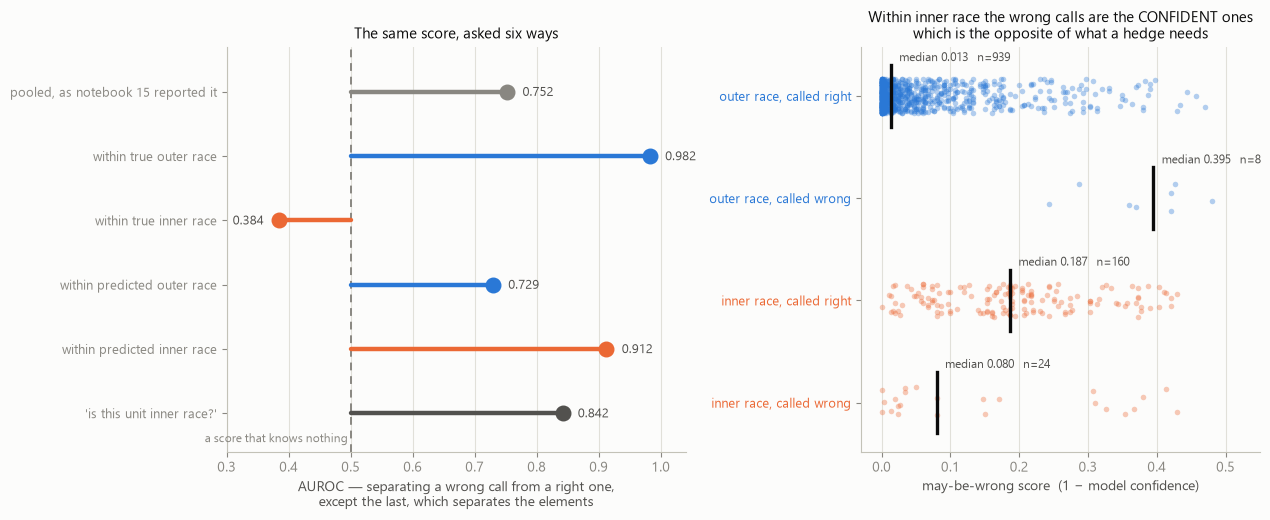

pooled wrong-call AUROC 0.752, but 'is this inner race?' scores 0.842 on the same numbers
within true outer race 0.982; within true inner race 0.384 — below chance
conditioned on the call the system actually makes: predicted outer 0.729, predicted inner 0.912


,AUROC
"pooled, as notebook 15 reported it",0.752
within true outer race,0.982
within true inner race,0.384
within predicted outer race,0.729
within predicted inner race,0.912
'is this unit inner race?',0.842


In [2]:
def auroc(mask, target):
    m = mask.to_numpy() if hasattr(mask, "to_numpy") else mask
    t = target[m]
    return roc_auc_score(t.astype(int), J.loc[m, "hedge"]) if t.nunique() > 1 else np.nan


ALL = pd.Series(True, index=J.index)
wrong = ~J["ok"]
QUESTIONS = [("pooled, as notebook 15 reported it", auroc(ALL, wrong), MUTED),
             ("within true outer race", auroc(J["truth"] == "OR", wrong), C_BLUE),
             ("within true inner race", auroc(J["truth"] == "IR", wrong), C_ORANGE),
             ("within predicted outer race", auroc(J["pred"] == "OR", wrong), C_BLUE),
             ("within predicted inner race", auroc(J["pred"] == "IR", wrong), C_ORANGE),
             ("'is this unit inner race?'", auroc(ALL, J["truth"] == "IR"), INK2)]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1.15, 1]))
y = np.arange(len(QUESTIONS))
# a lollipop anchored at 0.5, not a bar from zero: the quantity of interest is the
# distance from "knows nothing", and a bar on a truncated axis would misencode it
axa.axvline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
for i, (_, v, c) in enumerate(QUESTIONS):
    axa.plot([0.5, v], [i, i], color=c, lw=3.2, solid_capstyle="round", zorder=3)
    axa.scatter([v], [i], s=110, color=c, zorder=4)
    axa.annotate(f"{v:.3f}", (v, i), xytext=(11 if v > 0.5 else -11, -3),
                 textcoords="offset points", fontsize=9.5, color=INK2,
                 ha="left" if v > 0.5 else "right")
axa.text(0.5, len(QUESTIONS) - 0.55, "a score that knows nothing ", fontsize=8.5,
         color=MUTED, ha="right")
axa.set_yticks(y, [q for q, _, _ in QUESTIONS], fontsize=9.5)
axa.invert_yaxis()
axa.set_xlim(0.3, 1.04)
axa.set_ylim(len(QUESTIONS) - 0.4, -0.7)
axa.grid(axis="y", visible=False)
axa.set_xlabel("AUROC — separating a wrong call from a right one,\nexcept the last, which separates the elements")
axa.set_title("The same score, asked six ways", fontsize=11)

rng = np.random.default_rng(0)
pos = {("OR", True): 0, ("OR", False): 1, ("IR", True): 2, ("IR", False): 3}
for (e, ok_), p in pos.items():
    v = J.loc[(J["truth"] == e) & (J["ok"] == ok_), "hedge"].to_numpy()
    axb.scatter(v, p + rng.uniform(-0.17, 0.17, len(v)), s=16, alpha=0.35,
                color=FCOLOR[e], zorder=3, linewidths=0)
    axb.plot([np.median(v)] * 2, [p - 0.3, p + 0.3], color=INK, lw=2.4, zorder=5)
    axb.annotate(f"median {np.median(v):.3f}   n={len(v)}", (np.median(v), p - 0.34),
                 xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK2)
axb.set_yticks(list(pos.values()),
               ["outer race, called right", "outer race, called wrong",
                "inner race, called right", "inner race, called wrong"], fontsize=9.5)
for i, (e, _) in enumerate(pos):
    axb.get_yticklabels()[i].set_color(FCOLOR[e])
axb.invert_yaxis()
axb.set_xlim(-0.03, 0.55)
axb.grid(axis="y", visible=False)
axb.set_xlabel("may-be-wrong score  (1 − model confidence)")
axb.set_title("Within inner race the wrong calls are the CONFIDENT ones\n"
              "which is the opposite of what a hedge needs", fontsize=11)
plt.tight_layout()
plt.show()

print(f"pooled wrong-call AUROC {QUESTIONS[0][1]:.3f}, "
      f"but 'is this inner race?' scores {QUESTIONS[5][1]:.3f} on the same numbers")
print(f"within true outer race {QUESTIONS[1][1]:.3f}; "
      f"within true inner race {QUESTIONS[2][1]:.3f} — below chance")
print(f"conditioned on the call the system actually makes: predicted outer "
      f"{QUESTIONS[3][1]:.3f}, predicted inner {QUESTIONS[4][1]:.3f}")
pd.DataFrame({"AUROC": [v for _, v, _ in QUESTIONS]},
             index=[q for q, _, _ in QUESTIONS]).style.format("{:.3f}")

**The 0.752 is largely an inner-race detector.** Asked to separate an
inner-race unit from an outer-race one — a question it was never posed — the
same score reaches **0.842**, higher than the 0.752 it earns on the question it
was built for. Inner-race units are both less confidently called and far more
often wrong, and a pooled AUROC cannot tell those two facts apart.

Split by element the composite comes apart in the worst possible way. Within
outer race the flag is nearly perfect at **0.982**; within inner race it is
**0.384** — *below chance*, meaning that among inner-race snapshots the calls
the model is least sure of are the ones it is most likely to get **right**. The
right panel is the mechanism: the 24 wrong inner-race calls sit at a median
score of **0.080** while the 160 right ones sit at **0.187**. They are the
confident ones. Outer race behaves the way a hedge needs — its 8 wrong calls sit
at 0.395 against 0.013 for the 939 right ones — which is exactly why pooling the
two classes produces a number that looks usable.

That is notebook 15's finding 6 arriving as a number. A freshly alarmed
inner-race bearing looks like a textbook early outer race, so the model is not
hesitant about it — it is wrong and sure. A hedge keyed to hesitation cannot
catch a confident error by construction.

There is one genuinely useful line in the panel. Conditioned on the **predicted**
element — which, unlike the true element, is something a deployed system
actually holds — the score is usable in both branches: **0.729** where it says
outer race, **0.912** where it says inner race. Whether that survives a
threshold is the next question, and it is a different question from whether the
AUROC is high.

## What a threshold does, and what nesting does to it

An AUROC is a property of a ranking; a hedge is a property of a cut point. The
left panel takes the obvious implementation — **one global threshold**, hedge
every snapshot whose score exceeds it — and reports the error rate among the
calls that are still spoken, decomposed by element.

The right panel then does it properly. Thresholds are picked **per predicted
element** and **nested**: chosen on ten units, applied to the eleventh, so the
held-out unit contributes nothing to the cut point it is scored against. Because
a selection rule can overfit as easily as a model, two rules are compared — one
that hunts for the loosest threshold meeting a residual-error target, and one
that simply hedges a fixed share of each branch.

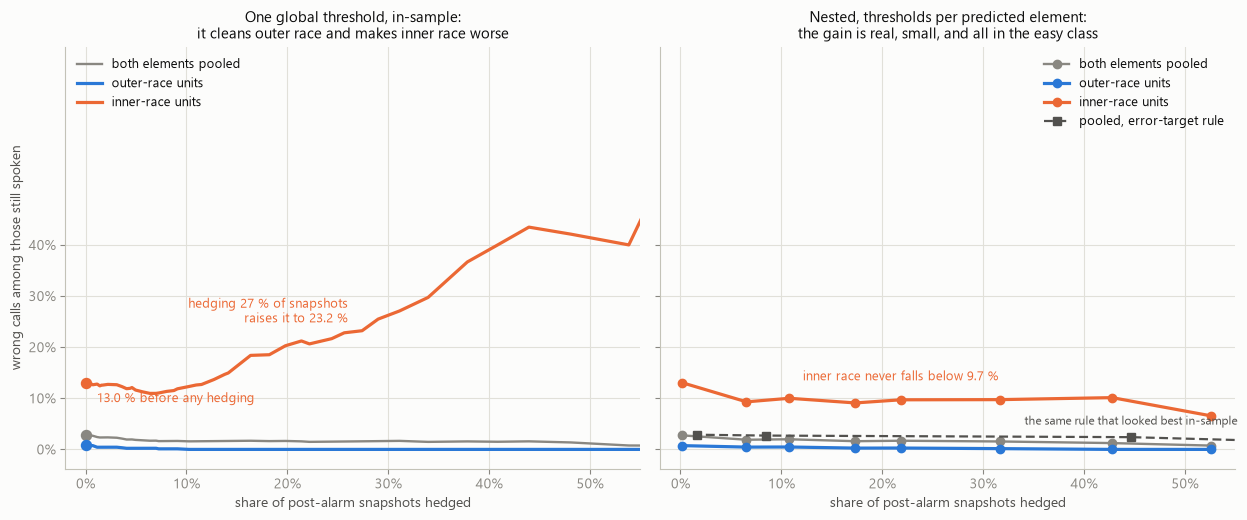

one global threshold at 0.10: hedges 27.4%, pooled error 1.58% — but outer race 0.00% and inner race 23.21%, against 13.04% with no hedging at all
nested, per predicted element, hedging 21.8%: pooled 1.70% (outer 0.27%, inner 9.70%), unit vote 11/11
the error-target rule is the one that overfits: in-sample it reached 0.77 %, nested it reaches 2.40% while hedging 44.7%
wrote xjtu_contract_nested.csv, xjtu_contract_global.csv


In [3]:
TAUS = np.round(np.arange(0.0, 0.51, 0.01), 2)
glob = []
for t in TAUS:
    un = J["hedge"] <= t
    row = dict(tau=t, silence=(~un).mean())
    for nm, m in (("all", ALL), ("OR", J["truth"] == "OR"), ("IR", J["truth"] == "IR")):
        s = un & m
        row[nm] = 1 - J.loc[s, "ok"].mean() if s.any() else np.nan
    glob.append(row)
glob = pd.DataFrame(glob)

GRID = np.round(np.arange(0.50, 0.005, -0.01), 2)


def rule_target(train, e, arg):
    """loosest threshold whose residual error on the TRAINING units clears a target"""
    s = train[train["pred"] == e]
    for t in GRID:
        un = s["hedge"] <= t
        if un.sum() >= 10 and (1 - s.loc[un, "ok"].mean()) <= arg:
            return t
    return 0.0


def rule_share(train, e, arg):
    """hedge a fixed share of this branch, whatever that costs"""
    s = train[train["pred"] == e]
    return float(np.quantile(s["hedge"], arg)) if len(s) else 0.0


def nested(fn, arg):
    keep = wrong_left = total = 0
    per = {"OR": [0, 0], "IR": [0, 0]}
    votes = 0
    for held in RACE:
        tr, te = J[J["Bearing"] != held], J[J["Bearing"] == held]
        tau = {e: fn(tr, e, arg) for e in ("OR", "IR")}
        k = te["hedge"] <= te["pred"].map(tau)
        keep += k.sum()
        wrong_left += (~te.loc[k, "ok"]).sum()
        total += len(te)
        per[FAULT[held]][0] += k.sum()
        per[FAULT[held]][1] += (~te.loc[k, "ok"]).sum()
        votes += bool(k.any() and te.loc[k, "pred"].mode()[0] == FAULT[held])
    return dict(silence=1 - keep / total, resid=wrong_left / max(keep, 1),
                OR=per["OR"][1] / max(per["OR"][0], 1), IR=per["IR"][1] / max(per["IR"][0], 1),
                votes=votes, spoken=keep, wrong=wrong_left)


SHARES = [1.00, 0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50]
nest = pd.DataFrame([nested(rule_share, s) for s in SHARES])
targ = pd.DataFrame([nested(rule_target, t) for t in (0.005, 0.01, 0.02, 0.03)])

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3), sharey=True)
for nm, lab, col, lw in (("all", "both elements pooled", MUTED, 1.7),
                         ("OR", "outer-race units", C_BLUE, 2.3),
                         ("IR", "inner-race units", C_ORANGE, 2.3)):
    axa.plot(100 * glob["silence"], 100 * glob[nm], color=col, lw=lw, zorder=3, label=lab)
base = {nm: 100 * (1 - J.loc[J["truth"] == nm, "ok"].mean()) if nm != "all"
        else 100 * (~J["ok"]).mean() for nm in ("all", "OR", "IR")}
for nm, col in (("all", MUTED), ("OR", C_BLUE), ("IR", C_ORANGE)):
    axa.scatter([0], [base[nm]], s=52, color=col, zorder=5)
axa.annotate(f"{base['IR']:.1f} % before any hedging", (0, base["IR"]), xytext=(8, -14),
             textcoords="offset points", fontsize=9, color=C_ORANGE)
i274 = int(np.argmin(np.abs(glob["silence"] - 0.274)))
axa.annotate("hedging 27 % of snapshots\nraises it to 23.2 %",
             (100 * glob["silence"].iloc[i274], 100 * glob["IR"].iloc[i274]),
             xytext=(-10, 6), textcoords="offset points", fontsize=9, color=C_ORANGE,
             ha="right")
axa.set_xlim(-2, 55)
axa.set_xlabel("share of post-alarm snapshots hedged")
axa.set_ylabel("wrong calls among those still spoken")
axa.set_yticks([0, 10, 20, 30, 40], ["0%", "10%", "20%", "30%", "40%"])
axa.set_xticks([0, 10, 20, 30, 40, 50], ["0%", "10%", "20%", "30%", "40%", "50%"])
axa.legend(fontsize=9, loc="upper left")
axa.set_title("One global threshold, in-sample:\nit cleans outer race and makes inner race worse",
              fontsize=11)

for nm, lab, col, lw in (("resid", "both elements pooled", MUTED, 1.7),
                         ("OR", "outer-race units", C_BLUE, 2.3),
                         ("IR", "inner-race units", C_ORANGE, 2.3)):
    axb.plot(100 * nest["silence"], 100 * nest[nm], color=col, lw=lw, marker="o", ms=6,
             zorder=3, label=lab)
axb.plot(100 * targ["silence"], 100 * targ["resid"], color=INK2, lw=1.6, ls=(0, (4, 2)),
         marker="s", ms=6, zorder=4, label="pooled, error-target rule")
axb.annotate("the same rule that looked best in-sample", (100 * targ["silence"].iloc[1],
             100 * targ["resid"].iloc[1]), xytext=(0, 9), textcoords="offset points",
             fontsize=8.5, color=INK2, ha="center")
axb.annotate("inner race never falls below 9.7 %", (100 * nest["silence"].iloc[4],
             100 * nest["IR"].iloc[4]), xytext=(0, 14), textcoords="offset points",
             fontsize=9, color=C_ORANGE, ha="center")
axb.set_xlim(-2, 55)
axb.set_xlabel("share of post-alarm snapshots hedged")
axb.set_xticks([0, 10, 20, 30, 40, 50], ["0%", "10%", "20%", "30%", "40%", "50%"])
axb.legend(fontsize=9, loc="upper right")
axb.set_title("Nested, thresholds per predicted element:\nthe gain is real, small, and all in the easy class",
              fontsize=11)
plt.tight_layout()
plt.show()

g10 = glob[glob["tau"] == 0.10].iloc[0]
print(f"one global threshold at 0.10: hedges {g10['silence']:.1%}, pooled error "
      f"{g10['all']:.2%} — but outer race {g10['OR']:.2%} and inner race {g10['IR']:.2%}, "
      f"against {base['IR'] / 100:.2%} with no hedging at all")
n20 = nest[nest["silence"].sub(0.218).abs() < 0.02]
r = n20.iloc[0] if len(n20) else nest.iloc[4]
print(f"nested, per predicted element, hedging {r['silence']:.1%}: pooled {r['resid']:.2%} "
      f"(outer {r['OR']:.2%}, inner {r['IR']:.2%}), unit vote {int(r['votes'])}/11")
print(f"the error-target rule is the one that overfits: in-sample it reached 0.77 %, "
      f"nested it reaches {targ['resid'].iloc[1]:.2%} while hedging {targ['silence'].iloc[1]:.1%}")
nest.assign(rule=[f"hedge loosest {1 - s:.0%} of each branch" for s in SHARES]) \
    .set_index("rule")[["silence", "resid", "OR", "IR", "votes"]] \
    .style.format({"silence": "{:.1%}", "resid": "{:.2%}", "OR": "{:.2%}", "IR": "{:.2%}"})
# Cached so build_registry.py can recompute the spoken-call error rates
nest.assign(rule=[f"hedge loosest {1 - s:.0%} of each branch" for s in SHARES]) \
    .to_csv(OUT / "xjtu_contract_nested.csv", index=False)
glob.to_csv(OUT / "xjtu_contract_global.csv", index=False)
print("wrote xjtu_contract_nested.csv, xjtu_contract_global.csv")


**A single global threshold makes the class that needs help worse.** At a cut of
0.10 the pooled error falls from 2.83 % to 1.58 %, which is the number a paper
would report. Decomposed, outer race goes 0.84 % → **0.00 %** and inner race
goes 13.04 % → **23.21 %**. The hedge is removing inner-race snapshots the model
had right and leaving behind a residue that is nearly twice as wrong. Notebook
09 banned accuracy-on-faulty-bearings for hiding exactly this kind of trade; the
pooled hedging curve hides it just as well.

**Nested and conditioned on the predicted element, the flag survives — as a bad
trade.** Hedging **21.8 %** of post-alarm snapshots takes the pooled error from
2.83 % to **1.70 %**. But the decomposition is the finding: outer race falls to
0.27 % while inner race, which carries 24 of the 32 errors, moves only 13.04 % →
**9.70 %**, and it does not improve further at any budget — hedging 43 % of
everything still leaves it at 10.13 %. Three quarters of the errors sit in a
class where four fifths of them are invisible to the flag.

**And the selection rule matters more than the threshold.** The rule that hunts
for the loosest cut meeting an error target reads 0.77 % in-sample and **2.40 %**
nested, against a no-hedging baseline of 2.83 % — it buys almost nothing while
looking like it buys everything. The dumb rule that hedges a fixed share of each
branch nests better. This is notebook 12's KA30 gate again, and it is the reason
nesting is not optional.

One thing does not break: **the unit-level vote stays 11/11 at every budget**.
Hedging never changes a diagnosis here, it only withholds snapshots. Whatever
the flag is for, it is not for improving the answer.

## Does a hesitant race call mean a worse estimate of the life left?

This is notebook 16's conjecture, and it is the one that would justify a single
joint calibration rather than two separate ones. It has a clean test. Every
post-alarm snapshot carries both a may-be-wrong score and a RUL floor whose
truth is known, so the question is directly measurable: **does a low-confidence
race call predict a floor that overstates the life remaining?**

The confound from the first figure has to be controlled again. Inner-race units
are both less confidently called (this notebook) and have their remaining life
overestimated on 100 % of snapshots (notebook 16, finding 6) — so a pooled
correlation between confidence and RUL error is guaranteed to be positive
whether or not any relationship exists *within* a unit.

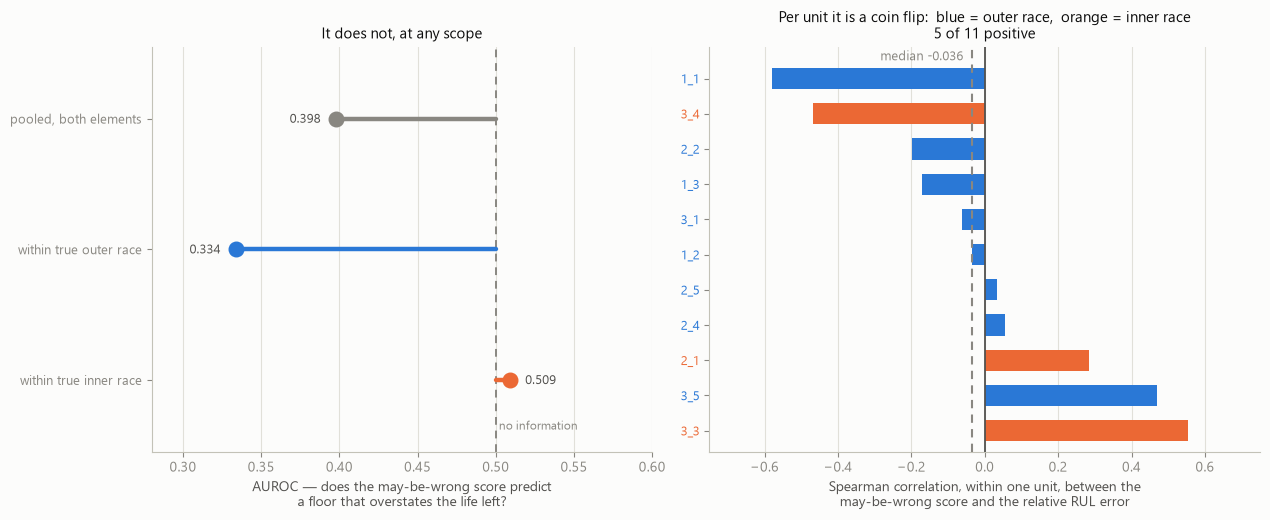

pooled: unsafe-floor AUROC 0.398, Spearman +0.168
within outer race 0.334 / +0.056;  within inner race 0.509 / +0.019
per unit: median rho -0.036, 5 of 11 positive, range -0.580 to +0.553


,auroc,rho
scope,,
"pooled, both elements",0.398,0.168
within true outer race,0.334,0.056
within true inner race,0.509,0.019


In [4]:
unsafe = J["q0.10"] > J["y"]                             # the floor overstates the life left
SCOPES = [("pooled, both elements", ALL, MUTED),
          ("within true outer race", J["truth"] == "OR", C_BLUE),
          ("within true inner race", J["truth"] == "IR", C_ORANGE)]

rows = []
for nm, m, col in SCOPES:
    u = unsafe[m]
    rows.append(dict(scope=nm, col=col,
                     auroc=roc_auc_score(u.astype(int), J.loc[m, "hedge"]) if u.nunique() > 1
                     else np.nan,
                     rho=spearmanr(J.loc[m, "hedge"], J.loc[m, "relerr"])[0]))
sc = pd.DataFrame(rows)

per = []
for b in RACE:
    s = J[J["Bearing"] == b]
    per.append(dict(unit=b.replace("Bearing", ""), truth=FAULT[b],
                    rho=spearmanr(s["hedge"], s["relerr"])[0], n=len(s)))
per = pd.DataFrame(per).sort_values("rho")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1, 1.1]))
y = np.arange(len(sc))
axa.axvline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
for i, (v, c) in enumerate(zip(sc["auroc"], sc["col"])):
    axa.plot([0.5, v], [i, i], color=c, lw=3.2, solid_capstyle="round", zorder=3)
    axa.scatter([v], [i], s=110, color=c, zorder=4)
    axa.annotate(f"{v:.3f}", (v, i), xytext=(11 if v > 0.5 else -11, -3),
                 textcoords="offset points", fontsize=9.5, color=INK2,
                 ha="left" if v > 0.5 else "right")
axa.text(0.5, len(sc) - 0.62, " no information", fontsize=8.5, color=MUTED)
axa.set_yticks(y, sc["scope"], fontsize=9.5)
axa.invert_yaxis()
axa.set_xlim(0.28, 0.60)
axa.set_ylim(len(sc) - 0.45, -0.55)
axa.grid(axis="y", visible=False)
axa.set_xlabel("AUROC — does the may-be-wrong score predict\na floor that overstates the life left?")
axa.set_title("It does not, at any scope", fontsize=11)

yy = np.arange(len(per))
axb.barh(yy, per["rho"], height=0.6, zorder=3,
         color=[FCOLOR[t] for t in per["truth"]])
axb.axvline(0, color=INK2, lw=1.3, zorder=4)
axb.axvline(per["rho"].median(), color=MUTED, lw=1.5, ls=(0, (4, 3)), zorder=4)
axb.annotate(f"median {per['rho'].median():+.3f}", (per["rho"].median(), -0.62),
             xytext=(-6, 0), textcoords="offset points", fontsize=9, color=MUTED,
             ha="right", va="center")
axb.set_ylim(len(per) - 0.4, -0.9)
axb.set_yticks(yy, per["unit"], fontsize=9.5)
for i, t in enumerate(per["truth"]):
    axb.get_yticklabels()[i].set_color(FCOLOR[t])
axb.set_xlim(-0.75, 0.75)
axb.grid(axis="y", visible=False)
axb.set_xlabel("Spearman correlation, within one unit, between the\n"
               "may-be-wrong score and the relative RUL error")
axb.set_title("Per unit it is a coin flip:  blue = outer race,  orange = inner race\n"
              f"{(per['rho'] > 0).sum()} of {len(per)} positive", fontsize=11)
plt.tight_layout()
plt.show()

print(f"pooled: unsafe-floor AUROC {sc['auroc'].iloc[0]:.3f}, "
      f"Spearman {sc['rho'].iloc[0]:+.3f}")
print(f"within outer race {sc['auroc'].iloc[1]:.3f} / {sc['rho'].iloc[1]:+.3f};  "
      f"within inner race {sc['auroc'].iloc[2]:.3f} / {sc['rho'].iloc[2]:+.3f}")
print(f"per unit: median rho {per['rho'].median():+.3f}, "
      f"{(per['rho'] > 0).sum()} of {len(per)} positive, "
      f"range {per['rho'].min():+.3f} to {per['rho'].max():+.3f}")
sc.set_index("scope")[["auroc", "rho"]].style.format("{:.3f}")

**The conjecture is refuted.** The may-be-wrong score carries no usable
information about whether the RUL floor is about to overstate the life
remaining: **0.398** pooled — if anything the hesitant snapshots are the
*safer* ones — **0.334** within outer race, **0.509** within inner race. Nothing
here is above chance in the direction the conjecture needs.

The pooled Spearman correlation of **+0.168** is the trap, and it is significant
at p ≈ 10⁻⁸ on 1131 snapshots. Within an element it collapses to +0.056 and
+0.019, and per unit the median is **−0.036** with 5 of 11 positive — a coin
flip. The pooled figure is the element confound and nothing else: inner-race
units happen to sit at both low confidence and high RUL error, and pooling reads
that co-occurrence as a relationship.

So **a low-confidence race call must not widen the RUL band.** The two hedges
are independent and have to be issued, and calibrated, separately. That is a
smaller contract than notebook 16 anticipated, and it is the one the measurement
supports. It also removes the only stated reason these two quantities needed a
joint calibration — which makes the next question, whether the floor should be
conditioned on the race call at all, worth asking rather than assuming.

## Should the floor be conditioned on the element either?

Notebook 16's finding 6 measured a large element split in RUL error — post-alarm
relative error 0.54 for outer race against 2.55 for inner race, optimistic on
76 % of snapshots against 100 % — and its next-steps asked for the floor to be
reported **per fault element**. That is a different claim from the one just
refuted, and it deserves its own test.

The test has to use the element the system *predicts*, not the one it turns out
to have, and that matters here: stage 2 mislabels early inner race as outer race,
so precisely the snapshots that need the tighter inner-race floor would be handed
the looser outer-race one. The left panel puts the per-element scheme on the same
safety–cost axes notebook 16 used, against a single global quantile. Both are
nested. The right panel asks why the answer comes out the way it does.

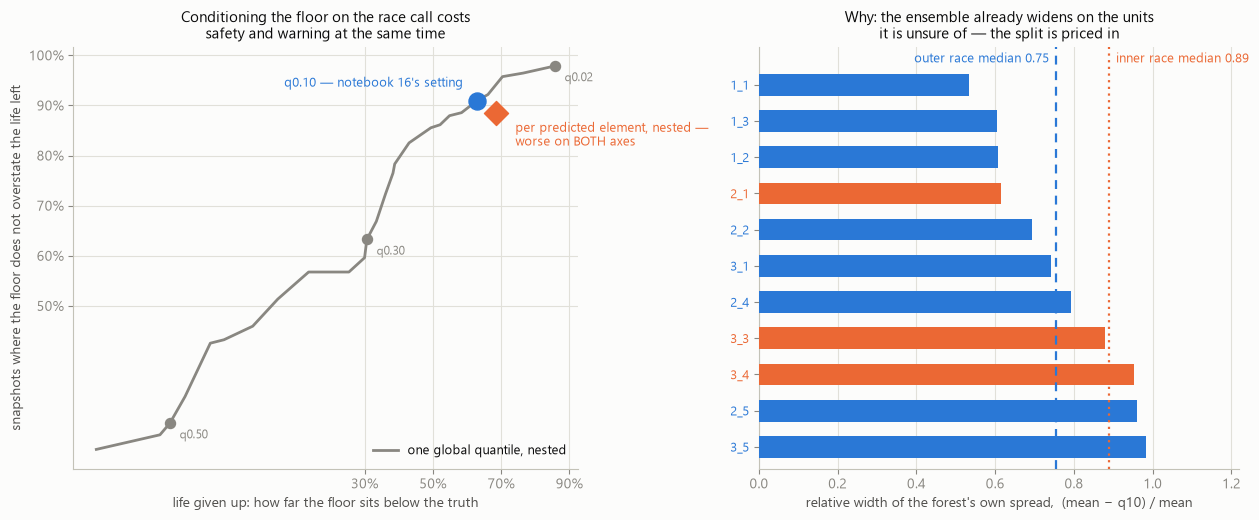

one global q0.10, nested: 91% safe, gives up 63%
per predicted element, nested: 89% safe, gives up 69% — worse on both axes
forest spread is already wider on inner race: 0.89 against 0.75


and safety is a per-unit property: at q0.10 the median unit is 91% safe but only 6 of 11 units individually clear 90 %


,safe,giveup
q,,
0.020000,97.87%,85.79%
0.060000,95.74%,70.44%
0.100000,90.96%,62.99%
0.140000,87.95%,54.91%
0.200000,82.53%,43.05%
0.300000,63.25%,30.67%


In [5]:
def score_floor(qmap, nested_pick=False):
    """safety and cost of a floor rule, per held-out unit"""
    sa, gu = [], []
    for held in RACE:
        te = J[J["Bearing"] == held]
        if nested_pick:
            tr = [b for b in RACE if b != held]
            qq = {}
            for e in ("OR", "IR"):
                best = QS[0]
                for q in QS:
                    v = [(J.loc[(J["Bearing"] == b) & (J["pred"] == e), f"q{q:.2f}"]
                          <= J.loc[(J["Bearing"] == b) & (J["pred"] == e), "y"]).mean()
                         for b in tr if ((J["Bearing"] == b) & (J["pred"] == e)).sum() >= 5]
                    if v and np.median(v) >= 0.90:
                        best = q
                qq[e] = best
        else:
            qq = qmap
        fl = np.array([te.iloc[i][f"q{qq[te.iloc[i]['pred']]:.2f}"] for i in range(len(te))])
        y = te["y"].to_numpy()
        k = y > 0
        sa.append((fl <= y).mean())
        gu.append(np.median((y[k] - fl[k]) / y[k]))
    return np.median(sa), np.median(gu), np.array(sa)


curve = [(q,) + score_floor({"OR": q, "IR": q})[:2] for q in QS]
curve = pd.DataFrame(curve, columns=["q", "safe", "giveup"])
pe_safe, pe_give, pe_all = score_floor(None, nested_pick=True)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1.05, 1]))
axa.plot(100 * curve["giveup"], 100 * curve["safe"], color=MUTED, lw=2.0, zorder=3,
         label="one global quantile, nested")
for q in (0.02, 0.30, 0.50):                             # 0.10 and 0.20 labelled separately
    r = curve[curve["q"] == q]
    if len(r):
        axa.scatter(100 * r["giveup"], 100 * r["safe"], s=52, color=MUTED, zorder=4)
        axa.annotate(f"q{q:.2f}", (100 * r["giveup"].iloc[0], 100 * r["safe"].iloc[0]),
                     xytext=(7, -11), textcoords="offset points", fontsize=8.5, color=MUTED)
axa.scatter([100 * pe_give], [100 * pe_safe], s=150, marker="D", color=C_ORANGE, zorder=6)
axa.annotate("per predicted element, nested —\nworse on BOTH axes",
             (100 * pe_give, 100 * pe_safe), xytext=(14, -6), textcoords="offset points",
             fontsize=9, color=C_ORANGE, ha="left", va="top")
r10 = curve[curve["q"] == 0.10].iloc[0]
axa.scatter([100 * r10["giveup"]], [100 * r10["safe"]], s=150, color=C_BLUE, zorder=6)
axa.annotate("q0.10 — notebook 16's setting", (100 * r10["giveup"], 100 * r10["safe"]),
             xytext=(-10, 10), textcoords="offset points", fontsize=9, color=C_BLUE, ha="right")
axa.set_xlabel("life given up: how far the floor sits below the truth")
axa.set_ylabel("snapshots where the floor does not overstate the life left")
axa.set_xticks([30, 50, 70, 90], ["30%", "50%", "70%", "90%"])
axa.set_yticks([50, 60, 70, 80, 90, 100], ["50%", "60%", "70%", "80%", "90%", "100%"])
axa.legend(fontsize=9, loc="lower right")
axa.set_title("Conditioning the floor on the race call costs\nsafety and warning at the same time",
              fontsize=11)

order = sorted(RACE, key=lambda b: J[J["Bearing"] == b]["width"].median())
yy = np.arange(len(order))
axb.barh(yy, [J[J["Bearing"] == b]["width"].median() for b in order], height=0.6, zorder=3,
         color=[FCOLOR[FAULT[b]] for b in order])
for e, ls, dy, ha in (("OR", (0, (4, 3)), -0.72, "right"), ("IR", (0, (1, 2)), -0.72, "left")):
    m = J[J["truth"] == e]["width"].median()
    axb.axvline(m, color=FCOLOR[e], lw=1.6, ls=ls, zorder=4)
    axb.annotate(f"{'outer' if e == 'OR' else 'inner'} race median {m:.2f}", (m, dy),
                 xytext=(-5 if ha == "right" else 5, 0), textcoords="offset points",
                 fontsize=9, color=FCOLOR[e], ha=ha, va="center")
axb.set_yticks(yy, [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    axb.get_yticklabels()[i].set_color(FCOLOR[FAULT[b]])
axb.set_ylim(len(order) - 0.4, -1.05)
axb.set_xlim(0, 1.22)                                    # bars must start at zero
axb.grid(axis="y", visible=False)
axb.set_xlabel("relative width of the forest's own spread,  (mean − q10) / mean")
axb.set_title("Why: the ensemble already widens on the units\nit is unsure of — the split is priced in",
              fontsize=11)
plt.tight_layout()
plt.show()

print(f"one global q0.10, nested: {r10['safe']:.0%} safe, gives up {r10['giveup']:.0%}")
print(f"per predicted element, nested: {pe_safe:.0%} safe, gives up {pe_give:.0%} "
      f"— worse on both axes")
print(f"forest spread is already wider on inner race: "
      f"{J[J['truth'] == 'IR']['width'].median():.2f} against "
      f"{J[J['truth'] == 'OR']['width'].median():.2f}")
print(f"and safety is a per-unit property: at q0.10 the median unit is {r10['safe']:.0%} safe "
      f"but only {(score_floor({'OR': 0.10, 'IR': 0.10})[2] >= 0.90).sum()} of 11 units "
      f"individually clear 90 %")
curve.set_index("q").loc[[0.02, 0.06, 0.10, 0.14, 0.20, 0.30]].style.format("{:.2%}")

**No. A single global quantile beats the per-element scheme on both axes at
once.** Nested, one global q0.10 is **91 %** safe and gives up **63 %** of the
life remaining; conditioning the quantile on the predicted element is **89 %**
safe and gives up **69 %**. There is no trade being made here — the conditioned
version is simply worse, and notebook 16's "report the floor per fault element"
does not survive being measured.

The right panel gives the mechanism, and it is the reason the result is not a
fluke of eleven units. **The forest already widens its own spread on the units it
is unsure of**: the relative width of the tree distribution is **0.89** on
inner-race units against **0.75** on outer-race ones. The element split notebook
16 found in the *error* is already priced into the *ensemble*, so cutting a
lower quantile for inner race charges for it twice. Bearing3_4 and 3_3 — two of
the three inner-race units — sit at 0.95 and 0.88, near the top of the range,
without being told what they are.

Conditioning also imports stage 2's own error. Of the 24 snapshots that are
truly inner race but called outer race, **20 fall in the first fifth after the
alarm** — so the scheme applies the looser floor exactly where notebook 16 says
the estimate is most optimistic.

One caveat belongs with the headline number, and it is a correction to how
notebook 16's 91 % should be read. **That is the median unit, not the fleet.**
At q0.10 only **6 of 11** units individually clear 90 % safety, and Bearing2_4 —
the 42-minute unit, the shortest life in the set — is 18 % safe. A floor is a
per-unit promise, and reporting it as a median over units understates how often
it is broken on the unit in front of you.

## The contract

What survives is narrower than what this notebook set out to calibrate, and it
is stateable. At every post-alarm minute the system emits four fields, each with
a measured rate behind it and a stated scope:

| field | value | measured rate |
|---|---|---|
| **alarm** | fired / not fired | fires at 58.7 % of life remaining (nb14), 15/15 units (nb13) |
| **race** | outer / inner, *conditional on being one of the two* | 94.1 % of snapshots, 11/11 units (nb14); "unknown" is not detectable (nb15) |
| **may-be-wrong** | hedged / spoken | hedging 21.8 % of snapshots takes error 2.83 % → 1.70 %, but inner race only 13.0 % → 9.7 % |
| **life** | "at least *n* minutes", post-alarm only | q0.10 floor, 91 % safe on the median unit, gives up 63 % of the life left |

The figure below is that contract executed at the one moment it matters most —
the minute the alarm fires — for all eleven units, with nothing hidden.

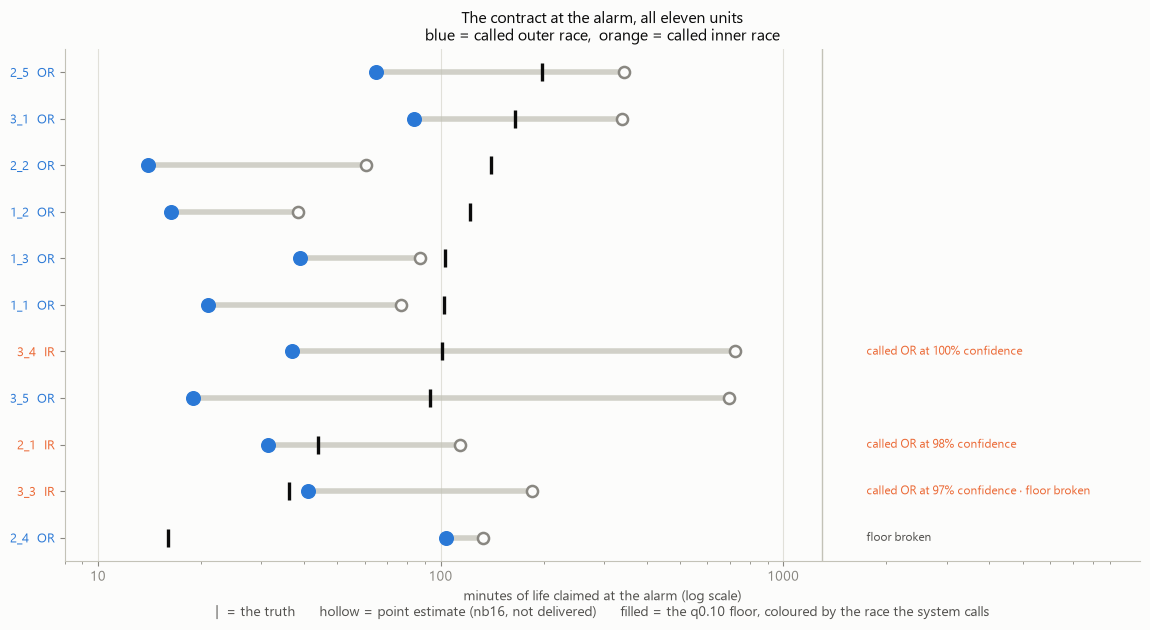

at the alarm: race right on 8/11, floor holds on 9/11, both right on 7/11
the point estimate notebook 16 declined to deliver would hold on 4/11
median floor 37 min against a median true remaining life of 102 min

the three wrong race calls at the alarm are all inner race called outer, at 100%, 98%, 97% confidence — which is why the flag cannot catch them


,unit,truth,call,conf,floor,y,ok,safe
0,2_5,OR,OR,0.87,65,198,True,True
1,3_1,OR,OR,0.93,84,165,True,True
2,2_2,OR,OR,0.97,14,140,True,True
3,1_2,OR,OR,0.97,16,122,True,True
4,1_3,OR,OR,0.99,39,103,True,True
5,1_1,OR,OR,0.99,21,102,True,True
6,3_4,IR,OR,1.00,37,101,False,True
7,3_5,OR,OR,0.92,19,93,True,True
8,2_1,IR,OR,0.98,31,44,False,True
9,3_3,IR,OR,0.97,41,36,False,False


In [6]:
rows = []
for b in RACE:
    s = J[J["Bearing"] == b].iloc[0]
    rows.append(dict(unit=b.replace("Bearing", ""), truth=FAULT[b], call=s["pred"],
                     conf=1 - s["hedge"], floor=s["q0.10"], point=s["point"],
                     y=s["y"], ok=s["pred"] == FAULT[b], safe=s["q0.10"] <= s["y"]))
A = pd.DataFrame(rows).sort_values("y", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11.6, 6.4))
NOTE_X = 1750                                            # a text column clear of every mark
for i, r in A.iterrows():
    ax.plot([r["floor"], r["point"]], [i, i], color=BASE, lw=4, alpha=0.75,
            solid_capstyle="round", zorder=2)
    ax.scatter([r["point"]], [i], s=64, facecolors=SURFACE, edgecolors=MUTED,
               linewidths=1.8, zorder=4)
    ax.scatter([r["floor"]], [i], s=96, color=FCOLOR[r["call"]], zorder=5)
    ax.scatter([r["y"]], [i], s=150, marker="|", color=INK, linewidths=2.4, zorder=6)
    note = []
    if not r["ok"]:
        note.append(f"called {r['call']} at {r['conf']:.0%} confidence")
    if not r["safe"]:
        note.append("floor broken")
    if note:
        ax.text(NOTE_X, i, " · ".join(note), fontsize=8.5, va="center",
                color=C_ORANGE if not r["ok"] else INK2)
ax.axvline(1300, color=BASE, lw=1.0, zorder=1)
ax.set_yticks(range(len(A)), [f"{r['unit']}  {r['truth']}" for _, r in A.iterrows()],
              fontsize=9.5)
for i, r in A.iterrows():
    ax.get_yticklabels()[i].set_color(FCOLOR[r["truth"]])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(8, 11000)
ax.set_xticks([10, 100, 1000], ["10", "100", "1000"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("minutes of life claimed at the alarm (log scale)\n"
              "|  = the truth      hollow = point estimate (nb16, not delivered)      "
              "filled = the q0.10 floor, coloured by the race the system calls")
ax.set_title("The contract at the alarm, all eleven units\n"
             "blue = called outer race,  orange = called inner race", fontsize=11.5)
plt.tight_layout()
plt.show()

print(f"at the alarm: race right on {A['ok'].sum()}/11, floor holds on {A['safe'].sum()}/11, "
      f"both right on {(A['ok'] & A['safe']).sum()}/11")
print(f"the point estimate notebook 16 declined to deliver would hold on "
      f"{(A['point'] <= A['y']).sum()}/11")
print(f"median floor {A['floor'].median():.0f} min against a median true remaining life of "
      f"{A['y'].median():.0f} min")
print(f"\nthe three wrong race calls at the alarm are all inner race called outer, at "
      f"{', '.join(f'{r.conf:.0%}' for r in A[~A['ok']].itertuples())} confidence — "
      f"which is why the flag cannot catch them")
A[["unit", "truth", "call", "conf", "floor", "y", "ok", "safe"]].style.format(
    {"conf": "{:.2f}", "floor": "{:.0f}", "y": "{:.0f}"})

**At the alarm the contract is right about the race on 8 of 11 units and holds
its floor on 9 of 11, and gets both right on 7.** The floor is worth what
notebook 16 said it was worth: it holds on 9 units where the point estimate
holds on 4.

The three wrong calls are the whole argument of this notebook in one line. All
three are **inner race called outer race**, and all three are made at **97 %,
98 % and 100 % confidence**. A hedge keyed to hesitation is silent on every one
of them. Bearing3_4 is the worst case available: called outer race at *full*
confidence, with 101 minutes left, and its floor — which does hold — promises 37.

Bearing2_4 is the other failure and a different one. It is the 42-minute unit,
the shortest life in the set; the floor promises 104 minutes when 16 remain. No
quantile of a forest trained on ten longer-lived units fixes that, which is
notebook 16's lifetime-versus-damage split showing up in the delivered artifact
rather than in a metric.

## What this changes

1. **Notebook 15's 0.752 is largely an element detector, not a wrongness
   detector.** The same score separates inner-race from outer-race units at
   **0.842** — better than the 0.752 it earns on the question it was built for.
   Split by element it is **0.982** within outer race and **0.384** within inner
   race, *below chance*: among inner-race snapshots the least confident calls are
   the ones most likely to be right.
2. **The errors that matter are confident errors.** The 24 wrong inner-race calls
   sit at a median may-be-wrong score of **0.080** against **0.187** for the 160
   right ones, while outer race behaves the way a hedge needs (0.395 wrong
   against 0.013 right). A freshly alarmed inner-race bearing is a textbook outer
   race, so the model is not hesitant about it — it is wrong and sure — and a
   hedge keyed to hesitation cannot catch that by construction.
3. **One global threshold makes the worse class worse.** At a cut of 0.10 the
   pooled error falls 2.83 % → 1.58 % while inner race rises **13.04 % →
   23.21 %**. The hedge strips out inner-race snapshots the model had right. Any
   threshold on this flag must be set per predicted element, where the score is
   usable in both branches (**0.729** predicted outer, **0.912** predicted inner).
4. **Nested, the flag is real and a bad trade.** Hedging **21.8 %** of post-alarm
   snapshots buys 2.83 % → **1.70 %** pooled, but inner race only 13.04 % →
   **9.70 %**, and it does not improve at any larger budget. The unit-level vote
   is 11/11 at every budget — hedging never changes a diagnosis, it only
   withholds snapshots.
5. **The selection rule overfits more than the threshold does.** Choosing the
   loosest cut that meets an error target reads **0.77 %** in-sample and
   **2.40 %** nested against a 2.83 % baseline. Hedging a fixed share of each
   branch nests better. This is notebook 12's KA30 gate a second time.
6. **Notebook 16's joint-calibration conjecture is refuted.** The may-be-wrong
   score does not predict a floor that overstates the life left: **0.398**
   pooled, **0.334** within outer race, **0.509** within inner race. The pooled
   Spearman of **+0.168** (p ≈ 10⁻⁸) is the element confound — within a unit the
   median is **−0.036**, 5 of 11 positive. **A low-confidence race call must not
   widen the RUL band**; the two hedges are independent.
7. **The floor should not be conditioned on the element either.** Nested, one
   global q0.10 is **91 %** safe giving up **63 %**; per predicted element it is
   **89 %** safe giving up **69 %** — worse on both axes. The mechanism is that
   the forest already widens on the units it is unsure of (relative spread
   **0.89** inner race against **0.75** outer race), so conditioning charges for
   the split twice and imports stage 2's own error, 20 of whose 24 misses fall in
   the first fifth after the alarm.
8. **A floor is a per-unit promise and should not be reported as a median over
   units.** At q0.10 the median unit is 91 % safe but only **6 of 11** units
   individually clear 90 %, and Bearing2_4 is **18 %** safe. Notebook 16's 91 %
   is correct and reads as more than it is.
9. **The contract, executed at the alarm: race right on 8/11, floor holds on
   9/11, both on 7/11** — against 4/11 for the point estimate notebook 16
   declined to deliver. All three wrong race calls are inner-race-called-outer at
   97–100 % confidence.